# 17 - Feedback-condition breakdown, LOSO significance, and subject-exclusion robustness

Supplementary analysis notebook written to support the thesis text. It does **not** retrain any of the three main models (RF/EEGForest, EEGNet, GAT-GRU-Transformer) -- it reads the already-cached LOSO result pickles in `out/results/` (produced by `15_classification.ipynb`) read-only, except for Task 4, which trains a lightweight EEGNet LOSO variant with two subjects excluded.

The current dataset contains 19 subjects (`subject_21` ... `subject_40`, no `subject_31`), so the base LOSO runs have 19 folds. Fold counts below are read from the data rather than hard-coded.

Four sections, matching the thesis's requested analyses:
1. Pooled precision/recall/F1/FPR + per-fold accuracy mean/std for RF, EEGNet, Transformer (base LOSO).
2. Paired Wilcoxon signed-rank tests across the LOSO folds (model vs model, and each model vs chance).
3. Feedback-condition breakdown of EEGNet's out-of-fold LOSO predictions (visual/auditory feedback, virtual hand, delayed feedback, hinting, choice trials, stimulus layout), restricted to true-pinch epochs.
4. A LOSO robustness check for EEGNet, excluding `subject_22` and `subject_26` (high epoch-rejection rate in `12_data_quality_analysis.ipynb`) from training and test entirely.

Outputs are written to `out/` (CSV + a markdown summary per section) and `out/figs/feedback_condition_accuracy.pdf` / `out/figs/feedback_condition_and_layout_accuracy.pdf`. Nothing under `data/`, `models/` or any other notebook is modified.

In [1]:
import pathlib, sys, os

ROOT = pathlib.Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Working directory:', pathlib.Path.cwd())

Working directory: C:\Users\nicol\github\VIBE\DataAnalysis


In [2]:
import gc
import pickle

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, fisher_exact, mannwhitneyu

RESULTS_DIR = ROOT / 'out' / 'results'
OUT_DIR = ROOT / 'out'
FIG_DIR = OUT_DIR / 'figs'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

POS_LABEL = 'PinchLog'
NEG_LABEL = 'NoPinchLog'

def print_markdown_table(df: pd.DataFrame):
    """Minimal markdown table printer (avoids a 'tabulate' dependency)."""
    cols = list(df.columns)
    widths = [max(len(str(c)), *(len(str(v)) for v in df[c])) for c in cols]
    header = '| ' + ' | '.join(c.ljust(w) for c, w in zip(cols, widths)) + ' |'
    sep = '| ' + ' | '.join('-' * w for w in widths) + ' |'
    print(header); print(sep)
    for _, row in df.iterrows():
        print('| ' + ' | '.join(str(row[c]).ljust(w) for c, w in zip(cols, widths)) + ' |')

## Task 1 - Pooled precision / recall / F1 / FPR + per-fold accuracy (base LOSO runs)

For each of RF (EEGForest), EEGNet and the GAT-GRU-Transformer, we load the base LOSO run (`{rf,eegnet,transformer}_leave_one_out_run.pkl`, one fold per subject). Each pkl is `{"data_version": ..., "result": {subject: {"result": <train_fn output dict>, "test_metadata": <pd.DataFrame>}}}` (verified by direct inspection -- see `scripts/inspect_results.py`). Row order in `test_metadata` matches `result['y_pred']` 1:1 because none of `train_eegnet` / `train_eegforest` / `train_gat_gru_transformer` shuffle their test DataLoader/array (checked in `models/EEGNet.py`, `models/EEGForest.py`, `models/GATGRU.py`), so `y_true` is read directly from `test_metadata['EventType']` for all three models rather than trusting a not-always-present `y_true` key.

The RF pkl is large (one fitted 400-tree RandomForestClassifier per fold embedded in it) -- loaded one model at a time with an explicit `del` + `gc.collect()` afterwards.

In [3]:
RUN_FILES = {
    'RF': 'rf_leave_one_out_run.pkl',
    'EEGNet': 'eegnet_leave_one_out_run.pkl',
    'Transformer': 'transformer_leave_one_out_run.pkl',
}

def load_run(fname):
    with open(RESULTS_DIR / fname, 'rb') as fh:
        cached = pickle.load(fh)
    return cached['result']

def extract_fold_arrays(fold_dict):
    meta = fold_dict['test_metadata']
    y_true = meta['EventType'].to_numpy()
    y_pred = np.asarray(fold_dict['result']['y_pred'])
    assert len(y_true) == len(y_pred), 'misaligned fold: y_true/y_pred length mismatch'
    return y_true, y_pred

def fold_metrics(y_true, y_pred):
    tp = int(np.sum((y_true == POS_LABEL) & (y_pred == POS_LABEL)))
    fn = int(np.sum((y_true == POS_LABEL) & (y_pred == NEG_LABEL)))
    fp = int(np.sum((y_true == NEG_LABEL) & (y_pred == POS_LABEL)))
    tn = int(np.sum((y_true == NEG_LABEL) & (y_pred == NEG_LABEL)))
    n = tp + fn + fp + tn
    acc = (tp + tn) / n
    majority = max(np.sum(y_true == POS_LABEL), np.sum(y_true == NEG_LABEL)) / n
    return dict(tp=tp, fn=fn, fp=fp, tn=tn, n=n, acc=acc, chance=majority)

In [4]:
per_model_fold_rows = []
per_model_pooled = {}

for model_name, fname in RUN_FILES.items():
    print(f'Loading {fname} ...')
    result = load_run(fname)
    subjects = list(result.keys())
    pooled = dict(tp=0, fn=0, fp=0, tn=0, n=0)
    for subj in subjects:
        y_true, y_pred = extract_fold_arrays(result[subj])
        m = fold_metrics(y_true, y_pred)
        per_model_fold_rows.append(dict(model=model_name, subject=subj, **m))
        for k in ('tp', 'fn', 'fp', 'tn', 'n'):
            pooled[k] += m[k]
    per_model_pooled[model_name] = pooled
    del result; gc.collect()
    print(f'  done, {len(subjects)} folds, pooled n={pooled["n"]}')

fold_df = pd.DataFrame(per_model_fold_rows)
N_FOLDS = fold_df['subject'].nunique()
assert (fold_df.groupby('model')['subject'].nunique() == N_FOLDS).all(), 'models were evaluated on different subject sets'
fold_df.to_csv(OUT_DIR / 'per_fold_accuracy_loso.csv', index=False)
fold_df.head()

Loading rf_leave_one_out_run.pkl ...


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


  done, 19 folds, pooled n=5376
Loading eegnet_leave_one_out_run.pkl ...
  done, 19 folds, pooled n=5376
Loading transformer_leave_one_out_run.pkl ...
  done, 19 folds, pooled n=5376


,model,subject,tp,fn,fp,tn,n,acc,chance
0,RF,subject_21,99,49,62,111,321,0.654206,0.538941
1,RF,subject_22,49,47,17,39,152,0.578947,0.631579
2,RF,subject_23,63,66,23,122,274,0.675182,0.529197
3,RF,subject_24,95,40,66,95,296,0.641892,0.543919
4,RF,subject_25,100,53,84,71,308,0.555195,0.503247


In [5]:
rows = []
for model_name in RUN_FILES:
    sub = fold_df[fold_df.model == model_name]
    acc_mean = sub['acc'].mean()
    # population std (ddof=0), also used for the Task 4 baseline
    acc_std = sub['acc'].std(ddof=0)
    chance_mean = sub['chance'].mean()

    p = per_model_pooled[model_name]
    tp, fn, fp, tn, n = p['tp'], p['fn'], p['fp'], p['tn'], p['n']
    precision = tp / (tp + fp) if (tp + fp) else float('nan')
    recall = tp / (tp + fn) if (tp + fn) else float('nan')
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float('nan')
    fpr = fp / (fp + tn) if (fp + tn) else float('nan')
    pooled_acc = (tp + tn) / n

    rows.append(dict(model=model_name, accuracy_mean=acc_mean, accuracy_std=acc_std,
                      pooled_accuracy=pooled_acc, precision=precision, recall=recall, f1=f1,
                      fpr=fpr, chance_mean=chance_mean, n_pooled=n, tp=tp, fn=fn, fp=fp, tn=tn))

metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(OUT_DIR / 'model_metrics_loso.csv', index=False)

print(f'### Model metrics (pooled across {N_FOLDS} LOSO folds, positive class = PinchLog)\n')
md_cols = ['model', 'accuracy_mean', 'accuracy_std', 'pooled_accuracy', 'precision', 'recall', 'f1', 'fpr', 'chance_mean']
md_tbl = metrics_df[md_cols].copy()
for c in md_cols[1:]:
    md_tbl[c] = md_tbl[c].map(lambda x: f'{x:.4f}')
print_markdown_table(md_tbl)
metrics_df

### Model metrics (pooled across 19 LOSO folds, positive class = PinchLog)

| model       | accuracy_mean | accuracy_std | pooled_accuracy | precision | recall | f1     | fpr    | chance_mean |
| ----------- | ------------- | ------------ | --------------- | --------- | ------ | ------ | ------ | ----------- |
| RF          | 0.6355        | 0.0516       | 0.6412          | 0.6408    | 0.6020 | 0.6208 | 0.3215 | 0.5314      |
| EEGNet      | 0.7003        | 0.0580       | 0.6977          | 0.6983    | 0.6698 | 0.6838 | 0.2757 | 0.5314      |
| Transformer | 0.6350        | 0.0654       | 0.6317          | 0.6104    | 0.6778 | 0.6423 | 0.4123 | 0.5314      |


,model,accuracy_mean,accuracy_std,pooled_accuracy,precision,recall,f1,fpr,chance_mean,n_pooled,tp,fn,fp,tn
0,RF,0.635471,0.051566,0.641183,0.640828,0.601982,0.620798,0.321467,0.531375,5376,1579,1044,885,1868
1,EEGNet,0.700328,0.058001,0.697731,0.698331,0.669844,0.683791,0.275699,0.531375,5376,1757,866,759,1994
2,Transformer,0.635031,0.065402,0.631696,0.610367,0.677850,0.642341,0.412278,0.531375,5376,1778,845,1135,1618


## Task 2 - Statistical significance across LOSO folds

Paired Wilcoxon signed-rank tests on the per-fold accuracies (one fold per held-out subject, paired by subject, since all three models were evaluated LOSO on the same subjects), for each of the 3 model pairs, plus each model's per-fold accuracy vs. that fold's own majority-class chance baseline.

In [6]:
pivot = fold_df.pivot(index='subject', columns='model', values='acc')
chance_pivot = fold_df.pivot(index='subject', columns='model', values='chance')

sig_rows = []
model_names = list(RUN_FILES.keys())
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        a, b = model_names[i], model_names[j]
        xa, xb = pivot[a].values, pivot[b].values
        diff = xa - xb
        stat, p = (float('nan'), 1.0) if np.allclose(diff, 0) else wilcoxon(xa, xb, zero_method='wilcox')
        sig_rows.append(dict(comparison=f'{a} vs {b}', statistic=stat, p_value=p,
                              mean_diff=diff.mean(), median_diff=np.median(diff), n_folds=len(diff)))

for m in model_names:
    xa, xc = pivot[m].values, chance_pivot[m].values
    diff = xa - xc
    stat, p = (float('nan'), 1.0) if np.allclose(diff, 0) else wilcoxon(xa, xc, zero_method='wilcox')
    sig_rows.append(dict(comparison=f'{m} vs chance', statistic=stat, p_value=p,
                          mean_diff=diff.mean(), median_diff=np.median(diff), n_folds=len(diff)))

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(OUT_DIR / 'model_significance_loso.csv', index=False)

print(f'### Paired Wilcoxon signed-rank tests (n={N_FOLDS} held-out subjects)\n')
sig_md = sig_df.copy()
for c in ('statistic', 'p_value', 'mean_diff', 'median_diff'):
    sig_md[c] = sig_md[c].map(lambda x: f'{x:.4g}')
print_markdown_table(sig_md)
sig_df

### Paired Wilcoxon signed-rank tests (n=19 held-out subjects)

| comparison            | statistic | p_value   | mean_diff | median_diff | n_folds |
| --------------------- | --------- | --------- | --------- | ----------- | ------- |
| RF vs EEGNet          | 7         | 7.248e-05 | -0.06486  | -0.05357    | 19      |
| RF vs Transformer     | 91        | 0.8906    | 0.0004406 | 0.01124     | 19      |
| EEGNet vs Transformer | 14        | 0.0004196 | 0.0653    | 0.06548     | 19      |
| RF vs chance          | 2         | 1.144e-05 | 0.1041    | 0.09651     | 19      |
| EEGNet vs chance      | 0         | 3.815e-06 | 0.169     | 0.1753      | 19      |
| Transformer vs chance | 3         | 1.907e-05 | 0.1037    | 0.0824      | 19      |


,comparison,statistic,p_value,mean_diff,median_diff,n_folds
0,RF vs EEGNet,7.0,0.000072,-0.064857,-0.053571,19
1,RF vs Transformer,91.0,0.890568,0.000441,0.011236,19
2,EEGNet vs Transformer,14.0,0.000420,0.065298,0.065476,19
3,RF vs chance,2.0,0.000011,0.104096,0.096515,19
4,EEGNet vs chance,0.0,0.000004,0.168953,0.175325,19
5,Transformer vs chance,3.0,0.000019,0.103655,0.082397,19


## Task 3 - Feedback-condition breakdown (EEGNet, out-of-fold LOSO predictions)

Answers the thesis's RQ on how visual/auditory feedback and related task factors affect EEG-based pinch detection. We use the EEGNet base LOSO run only (best-performing of the three and cheapest to align).

**Framing note (important):** the per-epoch feedback/task metadata columns (`hasVisualFeedback`, `hasAuditoryFeedback`, `hasVirtualHand`, `feedbackIsDelayed`, `pinchIsHinted`, `isChoiceStimuli`, `numberOfStimuli`) are only populated for `PinchLog` epochs -- every `NoPinchLog` epoch has all of them as `None`/`NaN` in this dataset (verified directly below). A false-positive-rate-by-condition breakdown for the negative class is therefore **not possible** with this metadata; there is nothing to group `NoPinchLog` epochs by. This notebook reports, for each condition flag, the **pinch detection rate** (= recall for the PinchLog class on the subset with that flag set) for flag=True vs flag=False, i.e. "given a real pinch happened under condition X, how often did EEGNet correctly detect it".

**Pinch subset:** only stimulus pinches (`EventName == 'PINCH_STIMULUS'`) are used. `PINCH_NONE` events (a pinch arriving without a gaze-confirmed target) are logged with `PinchType == 'PINCH'` and carry the block config, also in hinted blocks, whereas real hinted pinches are logged as `PINCH_WIZARD_OF_OZ` and are therefore excluded from the base run. Without this restriction, the *Pinch hinted* group would consist solely of `PINCH_NONE` events. The hinted comparison is instead taken from the hinted LOSO run (`eegnet_leave_one_out_hinted_run.pkl`, `PINCH_WIZARD_OF_OZ` counted as pinches): hinted vs. non-hinted stimulus pinches, both predicted by that same run.

**Out-of-fold aggregation:** each LOSO fold's `test_metadata` (PinchLog subset) + `y_pred` is concatenated. Because LOSO test sets partition the subjects exactly once, every PinchLog epoch appears exactly once in the pooled table, predicted by the model that did NOT see its subject during training -- the standard LOSO out-of-fold definition.

**Tests:** one two-sided Fisher exact test per condition flag on the 2x2 (flag True/False x detected/missed) table. Note that the tests are epoch-level on pooled predictions, i.e. they treat epochs as independent although they are nested within subjects.

In [7]:
with open(RESULTS_DIR / 'eegnet_leave_one_out_run.pkl', 'rb') as fh:
    _eegnet_cached = pickle.load(fh)
eegnet_result = _eegnet_cached['result']

_rows = []
for subj, fold in eegnet_result.items():
    meta = fold['test_metadata']
    y_pred = np.asarray(fold['result']['y_pred'])
    assert len(meta) == len(y_pred)
    sub = meta.copy()
    sub['y_pred'] = y_pred
    sub['subject_fold'] = subj
    _rows.append(sub)
full_oof = pd.concat(_rows, axis=0, ignore_index=True)

# confirm the framing note above: NoPinchLog epochs carry no feedback-condition metadata
BOOL_FLAGS = ['hasVisualFeedback', 'hasAuditoryFeedback', 'hasVirtualHand',
              'feedbackIsDelayed', 'pinchIsHinted', 'isChoiceStimuli']
print(full_oof.groupby('EventType')[BOOL_FLAGS].apply(lambda g: g.notna().sum()))

pinch = full_oof[full_oof['EventType'] == POS_LABEL].copy()
# stimulus pinches only: PINCH_NONE events (no gaze-confirmed target) would otherwise pose as hinted pinches
print(f"Dropping {int((pinch['EventName'] != 'PINCH_STIMULUS').sum())} PinchLog epochs without a stimulus target")
pinch = pinch[pinch['EventName'] == 'PINCH_STIMULUS'].copy()
pinch['detected'] = pinch['y_pred'] == POS_LABEL
n_total_pinch = len(pinch)
n_subjects = pinch['subject_fold'].nunique()
overall_recall = pinch['detected'].mean()
print(f'\nOut-of-fold PinchLog epochs (pooled): {n_total_pinch} from {n_subjects} subjects; '
      f'overall detection rate = {overall_recall:.4f}')

            hasVisualFeedback  hasAuditoryFeedback  hasVirtualHand  \
EventType                                                            
NoPinchLog                  0                    0               0   
PinchLog                 2623                 2623            2623   

            feedbackIsDelayed  pinchIsHinted  isChoiceStimuli  
EventType                                                      
NoPinchLog                  0              0                0  
PinchLog                 2623           2623             2623  
Dropping 207 PinchLog epochs without a stimulus target

Out-of-fold PinchLog epochs (pooled): 2416 from 19 subjects; overall detection rate = 0.6817


In [8]:
# real hinted pinches (PINCH_WIZARD_OF_OZ) are not part of the base run, so the hinted comparison uses the hinted
# LOSO run: hinted vs. non-hinted stimulus pinches, both predicted by that same run
with open(RESULTS_DIR / 'eegnet_leave_one_out_hinted_run.pkl', 'rb') as fh:
    _hinted_cached = pickle.load(fh)
if _hinted_cached.get('data_version') != _eegnet_cached.get('data_version'):
    print(f"WARNING: hinted run data_version {_hinted_cached.get('data_version')} differs from the base run "
          f"{_eegnet_cached.get('data_version')} -- rerun 15_classification.ipynb")
hinted_pinch = pd.concat([fold['test_metadata'].assign(y_pred=np.asarray(fold['result']['y_pred']), subject_fold=subj)
                          for subj, fold in _hinted_cached['result'].items()], ignore_index=True)
hinted_pinch = hinted_pinch[(hinted_pinch['EventType'] == POS_LABEL)
                            & (hinted_pinch['EventName'] == 'PINCH_STIMULUS')].copy()
hinted_pinch['detected'] = hinted_pinch['y_pred'] == POS_LABEL
del _hinted_cached

rows = []
for flag in BOOL_FLAGS:
    src = hinted_pinch if flag == 'pinchIsHinted' else pinch
    sub = src[src[flag].notna()].copy()
    sub[flag] = sub[flag].astype(bool)
    if sub[flag].nunique() < 2:
        print(f'[skip] {flag}: fewer than 2 distinct non-null values')
        continue
    grp = sub.groupby(flag)['detected'].agg(['sum', 'count'])
    n_true = int(grp.loc[True, 'count']) if True in grp.index else 0
    n_false = int(grp.loc[False, 'count']) if False in grp.index else 0
    det_true = int(grp.loc[True, 'sum']) if True in grp.index else 0
    det_false = int(grp.loc[False, 'sum']) if False in grp.index else 0
    rate_true = det_true / n_true if n_true else float('nan')
    rate_false = det_false / n_false if n_false else float('nan')
    table = [[det_true, n_true - det_true], [det_false, n_false - det_false]]
    odds_ratio, p_value = fisher_exact(table)
    rows.append(dict(condition=flag, n_true=n_true, detected_true=det_true,
                      detection_rate_true=rate_true, n_false=n_false, detected_false=det_false,
                      detection_rate_false=rate_false, diff_true_minus_false=rate_true - rate_false,
                      fisher_odds_ratio=odds_ratio, fisher_p_value=p_value))

ns = pinch[pinch['numberOfStimuli'].notna()].copy()
if ns['numberOfStimuli'].nunique() > 1:
    detected_vals = ns.loc[ns['detected'], 'numberOfStimuli']
    missed_vals = ns.loc[~ns['detected'], 'numberOfStimuli']
    u_stat, u_p = mannwhitneyu(detected_vals, missed_vals, alternative='two-sided')
    print(f'numberOfStimuli: detected mean={detected_vals.mean():.3f} (n={len(detected_vals)}), '
          f'missed mean={missed_vals.mean():.3f} (n={len(missed_vals)}), '
          f'Mann-Whitney U={u_stat:.1f}, p={u_p:.4g}')
    print(ns.groupby('numberOfStimuli')['detected'].agg(['mean', 'count']))

feedback_df = pd.DataFrame(rows)
feedback_df.to_csv(OUT_DIR / 'feedback_condition_breakdown.csv', index=False)
feedback_df

numberOfStimuli: detected mean=4.336 (n=1647), missed mean=4.430 (n=769), Mann-Whitney U=616677.5, p=0.2228
                     mean  count
numberOfStimuli                 
1.0              0.754098    183
4.0              0.676121   1516
6.0              0.675035    717


,condition,n_true,detected_true,detection_rate_true,n_false,detected_false,detection_rate_false,diff_true_minus_false,fisher_odds_ratio,fisher_p_value
0,hasVisualFeedback,1922,1326,0.689906,494,321,0.649798,0.040109,1.199053,0.093249
1,hasAuditoryFeedback,1933,1319,0.682359,483,328,0.679089,0.003270,1.015159,0.913055
2,hasVirtualHand,1183,831,0.702451,1233,816,0.661800,0.040651,1.206436,0.032412
3,feedbackIsDelayed,278,172,0.618705,2138,1475,0.689897,-0.071192,0.729364,0.019818
4,pinchIsHinted,611,401,0.656301,2416,1773,0.733858,-0.077556,0.692512,0.000191
5,isChoiceStimuli,519,327,0.630058,1897,1320,0.695836,-0.065778,0.744472,0.004822


In [9]:
lines = []
lines.append('# Feedback-condition breakdown (EEGNet, base LOSO, out-of-fold, PinchLog epochs only)\n')
lines.append(f'Pooled out-of-fold PinchLog epochs: {n_total_pinch} across {n_subjects} folds. '
             f'Overall detection rate: {overall_recall:.4f}. '
             f'p-values: two-sided Fisher exact test. '
             f"Stimulus pinches only (EventName == 'PINCH_STIMULUS'); pinchIsHinted is taken from the hinted LOSO run "
             f'(PINCH_WIZARD_OF_OZ vs. non-hinted stimulus pinches).\n')
lines.append('| condition | rate (True) | n (True) | rate (False) | n (False) | diff (T-F) | odds ratio | p-value |')
lines.append('|---|---|---|---|---|---|---|---|')
for r in rows:
    lines.append(f"| {r['condition']} | {r['detection_rate_true']:.4f} | {r['n_true']} | "
                 f"{r['detection_rate_false']:.4f} | {r['n_false']} | {r['diff_true_minus_false']:+.4f} | "
                 f"{r['fisher_odds_ratio']:.3f} | {r['fisher_p_value']:.4g} |")
md_text = '\n'.join(lines)
(OUT_DIR / 'feedback_condition_breakdown.md').write_text(md_text, encoding='utf-8')
print(md_text)

# Feedback-condition breakdown (EEGNet, base LOSO, out-of-fold, PinchLog epochs only)

Pooled out-of-fold PinchLog epochs: 2416 across 19 folds. Overall detection rate: 0.6817. p-values: two-sided Fisher exact test. Stimulus pinches only (EventName == 'PINCH_STIMULUS'); pinchIsHinted is taken from the hinted LOSO run (PINCH_WIZARD_OF_OZ vs. non-hinted stimulus pinches).

| condition | rate (True) | n (True) | rate (False) | n (False) | diff (T-F) | odds ratio | p-value |
|---|---|---|---|---|---|---|---|
| hasVisualFeedback | 0.6899 | 1922 | 0.6498 | 494 | +0.0401 | 1.199 | 0.09325 |
| hasAuditoryFeedback | 0.6824 | 1933 | 0.6791 | 483 | +0.0033 | 1.015 | 0.9131 |
| hasVirtualHand | 0.7025 | 1183 | 0.6618 | 1233 | +0.0407 | 1.206 | 0.03241 |
| feedbackIsDelayed | 0.6187 | 278 | 0.6899 | 2138 | -0.0712 | 0.729 | 0.01982 |
| pinchIsHinted | 0.6563 | 611 | 0.7339 | 2416 | -0.0776 | 0.693 | 0.0001914 |
| isChoiceStimuli | 0.6301 | 519 | 0.6958 | 1897 | -0.0658 | 0.744 | 0.004822 |


Wrote C:\Users\nicol\github\VIBE\DataAnalysis\out\figs\feedback_condition_accuracy.pdf


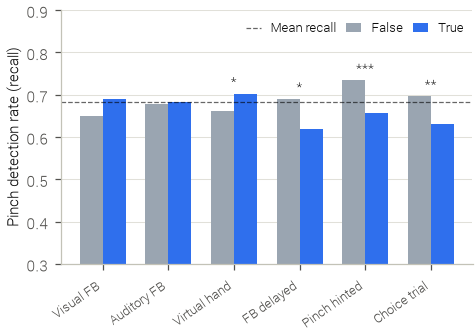

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import COL_W, TEXT_W
paper_style.apply()  # the import only styles once per kernel; re-apply so re-runs don't fall back to matplotlib defaults

labels_map = {
    'hasVisualFeedback': 'Visual FB', 'hasAuditoryFeedback': 'Auditory FB',
    'hasVirtualHand': 'Virtual hand', 'feedbackIsDelayed': 'FB delayed',
    'pinchIsHinted': 'Pinch hinted', 'isChoiceStimuli': 'Choice trial',
}
plot_df = feedback_df.copy()
plot_df['label'] = plot_df['condition'].map(labels_map)

def significance_stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''  # same levels as the teaser (20)

def plot_free_variables(ax, plot_df=plot_df):
    """Detection rate per condition flag (False/True), stars from Fisher exact tests."""
    x = np.arange(len(plot_df)); width = 0.35
    ax.bar(x - width / 2, plot_df['detection_rate_false'], width, label='False', color='#9aa5b1')
    ax.bar(x + width / 2, plot_df['detection_rate_true'], width, label='True', color='#2f6fed')
    for i, (_, r) in enumerate(plot_df.iterrows()):
        star = significance_stars(r['fisher_p_value'])
        if star:
            y = max(r['detection_rate_true'], r['detection_rate_false']) + 0.03
            ax.text(i, y-0.02, star, ha='center', va='bottom', fontsize=6)
    ax.axhline(overall_recall, color='black', linewidth=0.6, linestyle='--', alpha=0.6, label='Mean recall')
    ax.set_ylabel('Pinch detection rate (recall)')
    ax.set_xticks(x); ax.set_xticklabels(plot_df['label'], rotation=35, ha='right', fontsize=6)
    ax.set_ylim(0.3, 0.9)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc='upper right', ncol=3, handlelength=1.2, columnspacing=0.8)

fig, ax = plt.subplots(figsize=(COL_W, 2.4))
plot_free_variables(ax)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig_path = FIG_DIR / 'feedback_condition_accuracy.pdf'
fig.savefig(fig_path)
print(f'Wrote {fig_path}')
plt.show()

### Stimulus layout (Static_1 / Static_4 / Random_6)

The three stimulus setups from `experiment.md` map one-to-one onto the metadata: `Static_1_Stimuli` and `Static_4_Stimuli` are the `ExperimentStatic` blocks with `numberOfStimuli` = 1 and 4, and `Random_6_Stimuli` are the `ExperimentRandom` blocks with `numberOfStimuli` = 6 (checked below). Layout is a three-level factor rather than a True/False flag, so it gets its own panel next to the free-variable panel, sharing the y-axis (pinch detection rate) and the overall-detection reference line.

Tests: a chi-square test of independence on the 3x2 (layout x detected/missed) table as the omnibus test, then pairwise Fisher exact tests; brackets mark pairs with p < 0.05. The free-variable panel uses the same Fisher-test stars as `feedback_condition_accuracy.pdf`. Unlike `feedback_condition_accuracy.pdf`, the *Choice trial* variable in this figure only uses pinches without delayed feedback (both its True and False bars and its Fisher test), so the choice-trial effect is not driven by the delayed-feedback trials.

**Confound (important for interpretation):** layout is not manipulated independently of the other conditions. Every Static_1 block has visual + auditory feedback and the virtual hand; Random_6 blocks never show the virtual hand and contain more delayed-feedback and choice trials (see the table printed below). The layout effect therefore cannot be separated from these factors with this design. The detection rates restricted to non-delayed-feedback trials are printed as a partial check.

layout      Random_6  Static_1  Static_4
block_type                              
Random           717         0         0
Static             0       183      1516 

     layout  detected     n    rate
0  Static_1       138   183  0.7541
1  Static_4      1025  1516  0.6761
2  Random_6       484   717  0.6750

chi-square (3x2): chi2(2)=4.785, p=0.09141
          a         b  odds_ratio  p_value
0  Static_1  Static_4      1.4690   0.0351
1  Static_1  Random_6      1.4763   0.0396
2  Static_4  Random_6      1.0050   0.9614 

          hasVisualFeedback  hasAuditoryFeedback  hasVirtualHand  feedbackIsDelayed  pinchIsHinted  isChoiceStimuli
layout                                                                                                             
Static_1               1.00                 1.00            1.00               0.00            0.0             0.00
Static_4               0.89                 0.88            0.66               0.09            0.0             0.16
Random_6

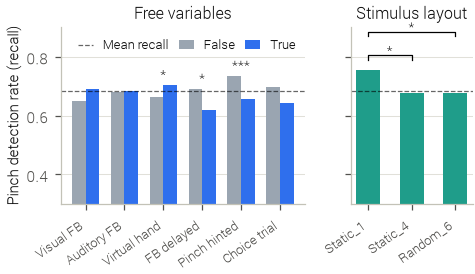

In [11]:
from scipy.stats import chi2_contingency

LAYOUT_LABELS = {1.0: 'Static_1', 4.0: 'Static_4', 6.0: 'Random_6'}

lay = pinch[pinch['numberOfStimuli'].notna()].copy()
lay['layout'] = lay['numberOfStimuli'].map(LAYOUT_LABELS)
lay['block_type'] = lay['ExperimentName'].str.extract(r'Experiments\.Experiment(\w+)\)')[0]
print(pd.crosstab(lay['block_type'], lay['layout']), '\n')  # Static <-> 1/4 stimuli, Random <-> 6

layout_order = list(LAYOUT_LABELS.values())
grp = lay.groupby('layout')['detected'].agg(['sum', 'count']).loc[layout_order]
grp['rate'] = grp['sum'] / grp['count']
table = np.column_stack([grp['sum'], grp['count'] - grp['sum']])
chi2, chi2_p, chi2_dof, _ = chi2_contingency(table)

pair_rows = []
for i in range(len(layout_order)):
    for j in range(i + 1, len(layout_order)):
        odds_ratio, p = fisher_exact([table[i], table[j]])
        pair_rows.append(dict(a=layout_order[i], b=layout_order[j], odds_ratio=odds_ratio, p_value=p))
pairs_df = pd.DataFrame(pair_rows)

layout_df = grp.rename(columns={'sum': 'detected', 'count': 'n'}).reset_index()
layout_df.to_csv(OUT_DIR / 'layout_breakdown.csv', index=False)
pairs_df.to_csv(OUT_DIR / 'layout_pairwise_fisher.csv', index=False)
print(layout_df.round(4))
print(f'\nchi-square ({len(layout_order)}x2): chi2({chi2_dof})={chi2:.3f}, p={chi2_p:.4g}')
print(pairs_df.round(4), '\n')

# confound check: share of each other condition within each layout, and rates without delayed feedback
print(lay.groupby('layout')[BOOL_FLAGS].apply(lambda g: g.astype(bool).mean()).loc[layout_order].round(2).to_string(), '\n')
no_delay = lay[~lay['feedbackIsDelayed'].astype(bool)]
print('Detection rate without delayed-feedback trials:')
print(no_delay.groupby('layout')['detected'].agg(['mean', 'count']).loc[layout_order].round(4))

# choice trials contain more delayed-feedback trials, so the choice-trial variable of this figure only uses
# non-delayed-feedback pinches (same Fisher test as the other flags)
choice = pinch[~pinch['feedbackIsDelayed'].astype(bool)]
is_choice = choice['isChoiceStimuli'].astype(bool)
det_true, n_true = int(choice.loc[is_choice, 'detected'].sum()), int(is_choice.sum())
det_false, n_false = int(choice.loc[~is_choice, 'detected'].sum()), int((~is_choice).sum())
odds_ratio, p_value = fisher_exact([[det_true, n_true - det_true], [det_false, n_false - det_false]])
plot_df_layout = plot_df.copy()
plot_df_layout.loc[plot_df_layout['condition'] == 'isChoiceStimuli',
                   ['n_true', 'detected_true', 'detection_rate_true', 'n_false', 'detected_false', 'detection_rate_false',
                    'diff_true_minus_false', 'fisher_odds_ratio', 'fisher_p_value']] = [
    n_true, det_true, det_true / n_true, n_false, det_false, det_false / n_false,
    det_true / n_true - det_false / n_false, odds_ratio, p_value]
print('\nChoice trial, non-delayed-feedback pinches only:')
print(plot_df_layout[plot_df_layout['condition'] == 'isChoiceStimuli'].round(4).to_string())

fig, (ax, ax_l) = plt.subplots(1, 2, figsize=(COL_W, 2), sharey=True,
                               gridspec_kw={'width_ratios': [len(plot_df_layout), len(layout_order)]})

# left: free variables as in feedback_condition_accuracy.pdf, choice trials without delayed feedback
plot_free_variables(ax, plot_df_layout)
ax.set_title('Free variables')

# right: stimulus layout, one bar per level
xl = np.arange(len(layout_order))
ax_l.bar(xl, grp['rate'], 0.55, color='#1f9d8a')
ax_l.axhline(overall_recall, color='black', linewidth=0.6, linestyle='--', alpha=0.6, label='Mean recall')
bracket_y = grp['rate'].max() + 0.05
for _, r in pairs_df[pairs_df['p_value'] < 0.05].iterrows():
    i, j = layout_order.index(r['a']), layout_order.index(r['b'])
    ax_l.plot([i, i, j, j], [bracket_y - 0.015, bracket_y, bracket_y, bracket_y - 0.015],
              color='black', linewidth=0.6)
    ax_l.text((i + j) / 2, bracket_y-0.01, significance_stars(r['p_value']), ha='center', va='bottom', fontsize=6)
    bracket_y += 0.08
ax_l.set_xticks(xl); ax_l.set_xticklabels(layout_order, rotation=35, ha='right', fontsize=6)
ax_l.set_title('Stimulus layout')
ax_l.yaxis.grid(True)
ax_l.set_axisbelow(True)

for a in (ax, ax_l):
    a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
fig.tight_layout()
fig_path = FIG_DIR / 'feedback_condition_and_layout_accuracy.pdf'
fig.savefig(fig_path)
print(f'Wrote {fig_path}')
plt.show()

### Task 3b - Alternative significance tests for the free variables

The pooled Fisher test above ignores that epochs are nested within subjects (between-subject differences in detection rate act as noise). This section re-tests the same 6 flags (same epoch subsets, same hinted-run source for `pinchIsHinted`) with:

- **Boschloo exact test**: an unconditional exact test for 2x2 tables, uniformly more powerful than Fisher's.
- **Cochran-Mantel-Haenszel (CMH)**: a 2x2xK test stratified by held-out subject. It compares True vs. False *within* each subject and pools the evidence, so between-subject differences do not count against the effect. It is the most appropriate epoch-level test for this design.
- **Subject-level paired Wilcoxon**: one detection rate per subject and condition (n = 19 pairs). It is the most conservative test because it uses subjects as the unit of analysis.
- **Within-subject permutation test**: the flag is shuffled within each subject (5000 permutations), with no distributional assumptions.
- **Joint logistic regression** with subject fixed effects and all 5 base-run flags as predictors. It checks whether each effect holds up once the others are controlled for (delayed feedback and choice trials co-occur, see the layout table).

All tests are two-sided. Choose the test *a priori* for the thesis text rather than reporting whichever comes out lowest.

In [12]:
from scipy.stats import boschloo_exact, chi2 as chi2_dist, norm, ttest_rel
from scipy.optimize import minimize

def cmh_test(d, flag):
    """Cochran-Mantel-Haenszel 2x2xK test stratified by subject (continuity-corrected) + MH common odds ratio."""
    num = var = or_num = or_den = 0.0
    for _, g in d.groupby('subject_fold'):
        x, y = g[flag].astype(bool), g['detected']
        a, b, c, e = (x & y).sum(), (x & ~y).sum(), (~x & y).sum(), (~x & ~y).sum()
        n, n1, m1 = a + b + c + e, a + b, a + c
        if n1 == 0 or n1 == n:  # subject has only one level of the flag -> no information
            continue
        num += a - n1 * m1 / n
        var += n1 * (n - n1) * m1 * (n - m1) / (n * n * (n - 1))
        or_num += a * e / n; or_den += b * c / n
    return or_num / or_den, chi2_dist.sf((abs(num) - 0.5) ** 2 / var, 1)

def within_subject_permutation(d, flag, n_perm=5000, seed=0):
    rng = np.random.default_rng(seed)
    x, y = d[flag].astype(bool).to_numpy(), d['detected'].to_numpy()
    groups = [np.flatnonzero(d['subject_fold'].to_numpy() == s) for s in d['subject_fold'].unique()]
    observed = abs(y[x].mean() - y[~x].mean()); hits = 0
    for _ in range(n_perm):
        xp = x.copy()
        for idx in groups:
            xp[idx] = rng.permutation(x[idx])
        hits += abs(y[xp].mean() - y[~xp].mean()) >= observed - 1e-12
    return (hits + 1) / (n_perm + 1)

alt_rows = []
for flag in BOOL_FLAGS:
    d = hinted_pinch if flag == 'pinchIsHinted' else pinch
    d = d[d[flag].notna()]
    x, y = d[flag].astype(bool), d['detected']
    table = [[(x & y).sum(), (x & ~y).sum()], [(~x & y).sum(), (~x & ~y).sum()]]
    per_subj = d.groupby(['subject_fold', x])['detected'].mean().unstack().dropna()
    mh_or, p_cmh = cmh_test(d, flag)
    alt_rows.append(dict(condition=flag, diff_pooled=y[x].mean() - y[~x].mean(),
                         diff_subject_mean=(per_subj[True] - per_subj[False]).mean(), n_subjects=len(per_subj),
                         p_fisher=fisher_exact(table)[1], p_boschloo=boschloo_exact(table).pvalue,
                         mh_odds_ratio=mh_or, p_cmh=p_cmh,
                         p_subject_wilcoxon=wilcoxon(per_subj[True], per_subj[False]).pvalue,
                         p_subject_ttest=ttest_rel(per_subj[True], per_subj[False]).pvalue,
                         p_permutation=within_subject_permutation(d, flag)))
alt_df = pd.DataFrame(alt_rows)

TESTS = ['p_fisher', 'p_boschloo', 'p_cmh', 'p_subject_wilcoxon', 'p_permutation']
alt_df.to_csv(OUT_DIR / 'feedback_condition_alternative_tests.csv', index=False)

print(alt_df[['condition', 'diff_pooled', 'diff_subject_mean', 'mh_odds_ratio'] + TESTS].round(4).to_string(), '\n')
print('Significant flags (p < 0.05) per test:')
for t in TESTS:
    print(f'  {t:20s} {alt_df.loc[alt_df[t] < 0.05, "condition"].map(labels_map).tolist()}')

# joint logistic regression with subject fixed effects (base run only; pinchIsHinted lives in the hinted run)
def logit_wald(X, y):
    nll = lambda b: np.sum(np.logaddexp(0, X @ b) - y * (X @ b))
    grad = lambda b: X.T @ (1 / (1 + np.exp(-X @ b)) - y)
    b = minimize(nll, np.zeros(X.shape[1]), jac=grad, method='BFGS', options={'gtol': 1e-8, 'maxiter': 5000}).x
    p = 1 / (1 + np.exp(-X @ b))
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None]))))
    return b, se

joint_flags = [f for f in BOOL_FLAGS if f != 'pinchIsHinted']
subj_dummies = pd.get_dummies(pinch['subject_fold'], drop_first=True).astype(float).to_numpy()
X = np.column_stack([np.ones(len(pinch)), pinch[joint_flags].astype(bool).astype(float).to_numpy(), subj_dummies])
beta, se = logit_wald(X, pinch['detected'].astype(float).to_numpy())
k = slice(1, len(joint_flags) + 1)
joint_df = pd.DataFrame(dict(condition=joint_flags, odds_ratio=np.exp(beta[k]), p_wald=2 * norm.sf(np.abs(beta / se))[k]))
joint_df.to_csv(OUT_DIR / 'feedback_condition_joint_logit.csv', index=False)
print('\nJoint logistic regression (detected ~ all flags + subject fixed effects):')
print(joint_df.round(4).to_string())


             condition  diff_pooled  diff_subject_mean  mh_odds_ratio  p_fisher  p_boschloo   p_cmh  p_subject_wilcoxon  p_permutation
0    hasVisualFeedback       0.0401             0.0559         1.2612    0.0932      0.0911  0.0420              0.1232         0.0932
1  hasAuditoryFeedback       0.0033             0.0043         0.9815    0.9131      0.8968  0.9140              0.8906         0.9226
2       hasVirtualHand       0.0407             0.0480         1.2404    0.0324      0.0321  0.0195              0.0108         0.0314
3    feedbackIsDelayed      -0.0712            -0.0938         0.6627    0.0198      0.0190  0.0034              0.0361         0.0188
4        pinchIsHinted      -0.0776            -0.0740         0.6399    0.0002      0.0002  0.0000              0.0446         0.0006
5      isChoiceStimuli      -0.0658            -0.0809         0.6771    0.0048      0.0048  0.0004              0.0160         0.0080 

Significant flags (p < 0.05) per test:
  p_fisher    

In [13]:
del eegnet_result, _eegnet_cached, full_oof, hinted_pinch
gc.collect()

9206

In [14]:
plot_df

,condition,n_true,detected_true,detection_rate_true,n_false,detected_false,detection_rate_false,diff_true_minus_false,fisher_odds_ratio,fisher_p_value,label
0,hasVisualFeedback,1922,1326,0.689906,494,321,0.649798,0.040109,1.199053,0.093249,Visual FB
1,hasAuditoryFeedback,1933,1319,0.682359,483,328,0.679089,0.003270,1.015159,0.913055,Auditory FB
2,hasVirtualHand,1183,831,0.702451,1233,816,0.661800,0.040651,1.206436,0.032412,Virtual hand
3,feedbackIsDelayed,278,172,0.618705,2138,1475,0.689897,-0.071192,0.729364,0.019818,FB delayed
4,pinchIsHinted,611,401,0.656301,2416,1773,0.733858,-0.077556,0.692512,0.000191,Pinch hinted
5,isChoiceStimuli,519,327,0.630058,1897,1320,0.695836,-0.065778,0.744472,0.004822,Choice trial


## Task 4 - Subject-exclusion robustness check (EEGNet, LOSO without subject_22 / subject_26)

`12_data_quality_analysis.ipynb` shows a high epoch-rejection rate for some subjects and suggests leaving out the worst measurements; `subject_22` and `subject_26` were flagged. Here we re-run the **LOSO** evaluation excluding those two subjects entirely from both training and test data (19 - 2 = 17 folds on the current dataset), for **EEGNet only** (scoped for time -- RF and the Transformer are skipped for this check). The baseline is the all-subject EEGNet LOSO run from Task 1, so both numbers always come from the same dataset version.

The training call below is copied **verbatim** from `15_classification.ipynb`'s `classify_cross_subject` (used by its `classify_leave_one_out` LOSO loop): `train_eegnet(..., log_wandb=False, n_epochs=150)`, `augment` left at its default (`False`) since the base LOSO run does not pass `augment=True`. The data-loading cell is also copied verbatim from `15_classification.ipynb`, with the only change being `read_raw_dataset(..., subjects_to_drop=['subject_22', 'subject_26'])` at load time.

**This retrains one EEGNet model per remaining subject from scratch (roughly 1 min per fold on an RTX 2070 SUPER GPU; also runnable standalone as `scripts/subject_exclusion_robustness.py`).** To keep this notebook fast to open/re-run by default, training is gated behind `RUN_TRAINING = False`, which instead loads the per-fold CSV already produced. The cell checks that the cached CSV covers exactly the expected subjects and raises if it was produced from an older dataset version -- set `RUN_TRAINING = True` (or run the script) to regenerate it.

In [15]:
RUN_TRAINING = False  # set True to actually retrain the EEGNet LOSO folds (~1 min per fold on GPU)

EXCLUDED_SUBJECTS = ['subject_22', 'subject_26']

# baseline = all-subject EEGNet LOSO run from Task 1 (same dataset version as everything else here)
_eegnet_folds = fold_df[fold_df.model == 'EEGNet']
BASELINE_N_FOLDS = len(_eegnet_folds)
BASELINE_MEAN = _eegnet_folds['acc'].mean()
BASELINE_STD = _eegnet_folds['acc'].std(ddof=0)
EXPECTED_SUBJECTS = sorted(set(_eegnet_folds['subject']) - set(EXCLUDED_SUBJECTS))
print(f'Baseline: {BASELINE_N_FOLDS}-fold EEGNet LOSO, mean={BASELINE_MEAN:.4f} std={BASELINE_STD:.4f}')
print(f'Exclusion run: {len(EXPECTED_SUBJECTS)} folds over {EXPECTED_SUBJECTS}')

Baseline: 19-fold EEGNet LOSO, mean=0.7003 std=0.0580
Exclusion run: 17 folds over ['subject_21', 'subject_23', 'subject_24', 'subject_25', 'subject_27', 'subject_28', 'subject_29', 'subject_30', 'subject_32', 'subject_33', 'subject_34', 'subject_35', 'subject_36', 'subject_37', 'subject_38', 'subject_39', 'subject_40']


In [16]:
def merge_epochs_dict(epochs_dict):
    """Copied from 15_classification.ipynb (read-only reuse, not an edit to that notebook)."""
    import mne
    all_epochs = []
    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()
            n = len(ep)
            extra = pd.DataFrame({'subject': [subj] * n, 'session': [sess] * n},
                                  index=ep.metadata.index if ep.metadata is not None else range(n))
            if ep.metadata is None:
                ep.metadata = extra
            else:
                meta = ep.metadata.copy()
                meta['subject'] = subj
                meta['session'] = sess
                ep.metadata = meta
            all_epochs.append(ep)
    return mne.concatenate_epochs(all_epochs)

def query_epochs(epochs, query):
    ep = epochs.copy()
    keep_idx = ep.metadata.query(query).index
    mask = ep.metadata.index.isin(keep_idx)
    return ep[mask]

def run_exclusion_eegnet_loso():
    import time
    from models.EEGNet import train_eegnet
    from scripts.dataset_manager import read_raw_dataset

    t_start = time.time()
    epoch_dict = read_raw_dataset(ROOT / 'data' / 'epoch_dataset_filtered', subjects_to_drop=EXCLUDED_SUBJECTS)
    assert not (set(EXCLUDED_SUBJECTS) & set(epoch_dict.keys()))

    epochs = merge_epochs_dict(epoch_dict)
    epochs_scaled = epochs.copy()
    epochs_scaled.load_data().apply_function(lambda x: (x - x.mean()) / (x.std() + 1e-12), channel_wise=True)
    filtered_epochs_scaled = query_epochs(
        epochs_scaled,
        "((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')",
    ).copy()

    subjects = filtered_epochs_scaled.metadata['subject'].unique().tolist()
    fold_rows = []
    for i, subject in enumerate(subjects, 1):
        t_fold = time.time()
        train_subjects = [s for s in subjects if s != subject]
        train_epochs = query_epochs(filtered_epochs_scaled, f'subject in {train_subjects}')
        test_epochs = query_epochs(filtered_epochs_scaled, f'subject in {[subject]}')
        result = train_eegnet(train_epochs, train_epochs.metadata.EventType,
                               test_epochs, test_epochs.metadata.EventType,
                               log_wandb=False, n_epochs=150)
        y_true = test_epochs.metadata['EventType'].to_numpy()
        y_pred = np.asarray(result['y_pred'])
        acc = float((y_true == y_pred).mean())
        print(f'[{i}/{len(subjects)}] held-out={subject} -> acc={acc:.4f} ({time.time()-t_fold:.1f}s)')
        fold_rows.append(dict(subject=subject, n_train=len(train_epochs), n_test=len(test_epochs), test_accuracy=acc))

    df = pd.DataFrame(fold_rows)
    print(f'Total wall time: {(time.time()-t_start)/60:.1f} min')
    return df

In [17]:
if RUN_TRAINING:
    per_fold_df = run_exclusion_eegnet_loso()
    per_fold_df.to_csv(OUT_DIR / 'subject_exclusion_robustness_per_fold.csv', index=False)
else:
    per_fold_df = pd.read_csv(OUT_DIR / 'subject_exclusion_robustness_per_fold.csv')
    print('Loaded precomputed per-fold results (RUN_TRAINING=False); '
          'see scripts/subject_exclusion_robustness.py for the standalone run.')

cached_subjects = sorted(per_fold_df['subject'])
if cached_subjects != EXPECTED_SUBJECTS:
    raise RuntimeError(
        f'subject_exclusion_robustness_per_fold.csv covers {len(cached_subjects)} subjects, expected '
        f'{len(EXPECTED_SUBJECTS)} for the current dataset (missing: '
        f'{sorted(set(EXPECTED_SUBJECTS) - set(cached_subjects))}). It is stale -- set RUN_TRAINING = True '
        f'or run scripts/subject_exclusion_robustness.py to regenerate it.')

n_excl = len(per_fold_df)
mean_acc = per_fold_df['test_accuracy'].mean()
std_acc = per_fold_df['test_accuracy'].std(ddof=0)
excl_label = f'{n_excl}-fold (excl. {", ".join(EXCLUDED_SUBJECTS)})'
base_label = f'{BASELINE_N_FOLDS}-fold (all subjects, baseline)'
print(f'\n{excl_label} EEGNet LOSO: mean={mean_acc:.4f} std={std_acc:.4f}')
print(f'{base_label}: mean={BASELINE_MEAN:.4f} std={BASELINE_STD:.4f}')
print(f'Delta (excluded - baseline): mean {mean_acc - BASELINE_MEAN:+.4f}, std {std_acc - BASELINE_STD:+.4f}')

summary = pd.DataFrame([
    dict(variant=base_label, n_folds=BASELINE_N_FOLDS, accuracy_mean=BASELINE_MEAN, accuracy_std=BASELINE_STD),
    dict(variant=excl_label, n_folds=n_excl, accuracy_mean=mean_acc, accuracy_std=std_acc),
])
summary.to_csv(OUT_DIR / 'subject_exclusion_robustness.csv', index=False)
summary

Loaded precomputed per-fold results (RUN_TRAINING=False); see scripts/subject_exclusion_robustness.py for the standalone run.

17-fold (excl. subject_22, subject_26) EEGNet LOSO: mean=0.6860 std=0.0616
19-fold (all subjects, baseline): mean=0.7003 std=0.0580
Delta (excluded - baseline): mean -0.0144, std +0.0036


,variant,n_folds,accuracy_mean,accuracy_std
0,"19-fold (all subjects, baseline)",19,0.700328,0.058001
1,"17-fold (excl. subject_22, subject_26)",17,0.685975,0.061604
